In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

### CSV Details

Meta/
Train/
Test

In [3]:
meta_csv = pd.read_csv("Inputs/Meta.csv")
train_csv = pd.read_csv("Inputs/Train.csv")
test_csv = pd.read_csv("Inputs/Test.csv")
display(meta_csv.head())
display(meta_csv.shape)
display(train_csv.head())
display(train_csv.shape)
display(test_csv.head())
display(test_csv.shape)

,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


(43, 5)

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


(39209, 8)

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


(12630, 8)

### Analyzing Shape and Colors of different Classes 

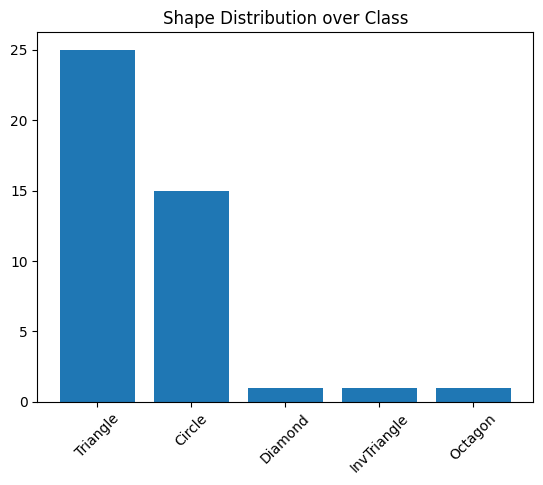

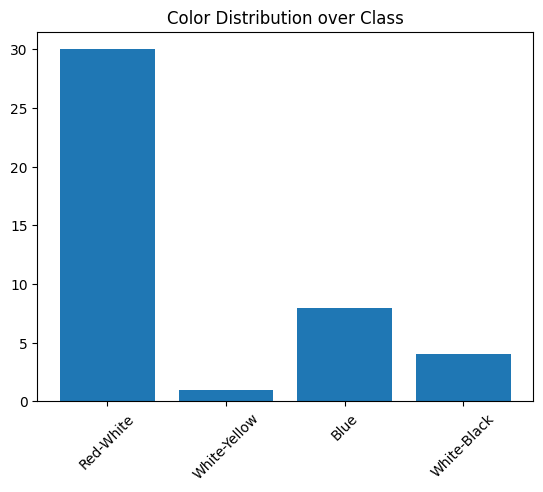

In [ ]:
plt.figure()

plt.bar(pd.unique(meta_csv["ShapeId"]),meta_csv['ShapeId'].value_counts())
plt.xticks(
    [0,1,2,3,4],
    ['Triangle', 'Circle', 'Diamond' , 'InvTriangle', 'Octagon'], 
    rotation=45, 
    fontsize=10)
plt.title("Shape Distribution over Class")
plt.show()
plt.close()

plt.figure()

plt.bar(pd.unique(meta_csv["ColorId"]),meta_csv['ColorId'].value_counts())
plt.xticks(
    [0,1,2,3],
    ['Red-White', 'White-Yellow', 'Blue', 'White-Black'],
    rotation=45, 
    fontsize=10)
plt.title("Color Distribution over Class")
plt.show()
plt.close()

In [5]:
train_path = Path("/home/bhuvan1707/Desktop/S5/Adaptive-Topology-Optimizer/Inputs/Train")
test_path = Path("/home/bhuvan1707/Desktop/S5/Adaptive-Topology-Optimizer/Inputs/Test")

train_class_distribution_images = dict()

with os.scandir(train_path) as entries:
    for i in entries:
        sub_dir = Path(i.path)
        image_count = 0
        if i.is_dir():
            for item in sub_dir.iterdir():
                if item.is_file() and item.suffix.lower() == '.png':
                    image_count+=1
        train_class_distribution_images[i.name]=image_count
print(sum(train_class_distribution_images.values()))

test_image_count=0
if test_path.is_dir():
    for item in test_path.iterdir():
        if item.is_file() and item.suffix.lower() == '.png':
            test_image_count+=1
test_image_count

39209


12630

In [6]:
train_class_distribution_images = {
    k: train_class_distribution_images[k] 
    for k in sorted(train_class_distribution_images.keys(), key=int)
}

test_class_distribution_images = dict()
for i in pd.unique(test_csv["ClassId"]):
    test_class_distribution_images[i]=len(test_csv[test_csv["ClassId"] == i])

test_class_distribution_images = {
    k: test_class_distribution_images[k] 
    for k in sorted(test_class_distribution_images.keys(), key=int)
}

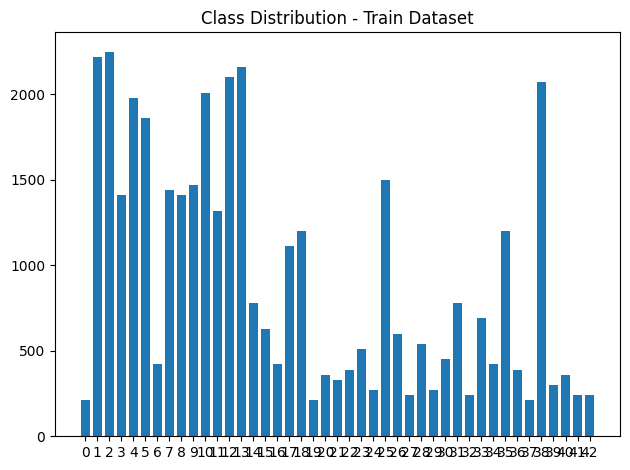

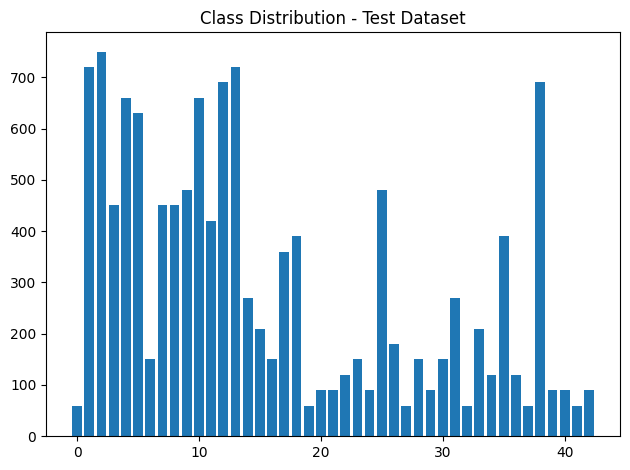

In [8]:
plt.figure()
plt.bar(train_class_distribution_images.keys(),train_class_distribution_images.values())
plt.title("Class Distribution - Train Dataset")
plt.tight_layout()
plt.show()
plt.close()

plt.figure()
plt.bar(test_class_distribution_images.keys(),test_class_distribution_images.values())
plt.title("Class Distribution - Test Dataset")
plt.tight_layout()
plt.show()
plt.close()